<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Atividade_Explanatoria_Interpolacao_Polinomial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpolação polinomial: compreender, explorar e comparar

**Cálculo Numérico | Atividade guiada no Google Colab**  


## Objetivos

Ao final, vocês deverão conseguir:

- distinguir interpolação de extrapolação;
- construir e avaliar um polinômio que passa por pontos dados;
- comparar formas de representação e reconhecer limitações numéricas;
- investigar como a escolha dos nós afeta o resultado.

> **Como usar:** leiam cada seção, executem as células de código e preencham os campos de resposta. As células com `# SUA RESPOSTA` podem ser editadas pelo grupo.

## 1. Ideia central: preencher valores entre medições

Suponha que uma tabela contenha medições $(x_i,y_i)$. Um polinômio interpolador $P(x)$ é escolhido para reproduzir exatamente os dados nos nós:

$$P(x_i)=y_i,\qquad i=0,1,\ldots,n.$$

Assim, se conhecemos medições em alguns instantes, podemos estimar a medida em um instante intermediário. A interpolação **não recupera automaticamente a realidade**: ela constrói uma curva compatível com os dados e com o método escolhido.

- **Interpolar:** estimar dentro do intervalo coberto pelos nós.
- **Extrapolar:** estimar fora desse intervalo; em geral, exige mais cautela.

**Antes de executar:** pensem numa situação em que seria útil estimar um valor entre duas medições. O que poderia tornar essa estimativa pouco confiável?

**Resposta do grupo:** Estimar a temperatura de um paciente às 10h, tendo medições às 8h e às 12h. A estimativa pode ser pouco confiável se: (i) houver ruído ou erro nas medições; (ii) a grandeza variar bruscamente entre as medições (um pico às 9h30 que nenhum dado captou); (iii) houver poucos pontos ou pontos muito distantes; (iv) o instante pedido estiver fora do intervalo medido (extrapolação). O polinômio só conhece os dados; o que acontece entre eles é suposição do método.

## 2. Dados, nós e grau

Os valores $x_i$ são chamados **nós**. Os pares $(x_i,y_i)$ são os dados que a curva deve reproduzir. Com $m$ nós distintos, existe um único polinômio de grau no máximo $m-1$ que passa por todos eles.

Por exemplo, quatro pontos determinam um polinômio de grau no máximo 3. O grau pode ser menor se os dados já pertencerem a um polinômio mais simples.

### Atenção à palavra “exatamente”
O polinômio construído passa pelos pontos informados (salvo pequenos erros de arredondamento computacional). Isso não garante que ele represente bem o comportamento entre pontos, nem que seja um bom modelo fora do intervalo.

**Previsão:** se acrescentarmos um ponto novo, o polinômio precisa continuar passando pelos pontos antigos? O formato da curva pode mudar?

**Resposta antes do teste:** O novo polinômio **precisa** continuar passando pelos pontos antigos (ele passa por *todos* os pontos, antigos e novo), mas o formato da curva **pode mudar**: o grau pode subir (até $m$ nós → grau ≤ $m$) e, em geral, **todos** os coeficientes mudam, inclusive entre os pontos antigos. Só não muda se o ponto novo já estiver sobre o polinômio anterior. A célula abaixo testa as duas situações.

In [1]:
# Teste da previsão: acrescentar um ponto novo aos dados do exemplo da seção 3
import numpy as np
x0 = np.array([-2, -1, 0, 1], dtype=float); y0 = np.array([9, 4, 1, 0], dtype=float)
P_antigo = np.polynomial.Polynomial.fit(x0, y0, 3).convert()

for novo in [(2.0, 1.0), (2.0, 5.0)]:     # (2,1) está sobre P_antigo; (2,5) não está
    xn = np.append(x0, novo[0]); yn = np.append(y0, novo[1])
    Pn = np.polynomial.Polynomial.fit(xn, yn, len(xn) - 1).convert()
    print(f"Ponto novo {novo}:  P_antigo({novo[0]:g}) = {P_antigo(novo[0]):.4f}")
    print("  novo polinômio:", Pn)
    print("  passa pelos pontos antigos? ", np.allclose(Pn(x0), y0), "| passa pelo novo? ", np.isclose(Pn(novo[0]), novo[1]))

Ponto novo (2.0, 1.0):  P_antigo(2) = 1.0000
  novo polinômio: 1.0 - 2.0·x + 1.0·x² - (9.67656468e-16)·x³ - (1.13342574e-16)·x⁴
  passa pelos pontos antigos?  True | passa pelo novo?  True
Ponto novo (2.0, 5.0):  P_antigo(2) = 1.0000
  novo polinômio: 1.0 - 2.33333333·x + 0.83333333·x² + 0.33333333·x³ + 0.16666667·x⁴
  passa pelos pontos antigos?  True | passa pelo novo?  True


## 3. Primeiro exemplo: observar antes de formalizar

Vamos usar quatro pontos. Observem os dados e descrevam o padrão que imaginam antes de ver a curva.

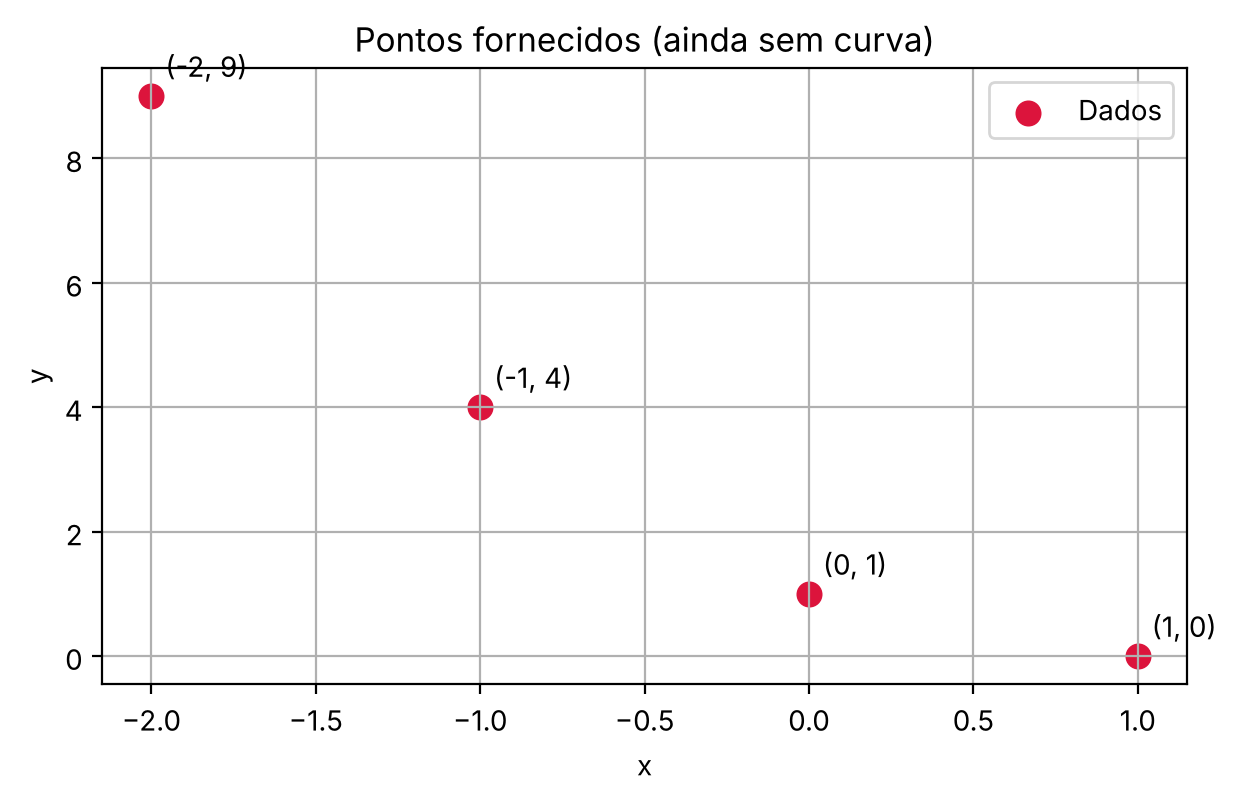

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=70, label="Dados")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi:g}, {yi:g})", (xi, yi), xytext=(5, 7), textcoords="offset points")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Pontos fornecidos (ainda sem curva)")
plt.grid(True); plt.legend(); plt.show()

**Descrevam a tendência dos pontos.** A curva precisa ser reta? Há mais de uma curva que poderia passar pelos pontos?

**Resposta:** $y$ decresce quando $x$ cresce, mas cada vez mais devagar: as quedas são $-5,\,-3,\,-1$ (a variação diminui de 2 em 2), o que sugere uma **parábola** (candidata: $y=(x-1)^2$). Não é reta, pois as inclinações entre pontos consecutivos não são iguais. E **há infinitas curvas** que passam pelos 4 pontos (splines, funções trigonométricas, polinômios de grau maior que 3 etc.); o que é único é o polinômio de grau ≤ 3.

## 4. Construindo o polinômio com uma ferramenta

Usaremos `numpy.polynomial.Polynomial.fit` para obter o polinômio de grau até $m-1$. O método faz o cálculo numericamente e depois convertemos para a forma usual em potências de $x$.

A expressão impressa pode conter coeficientes muito pequenos, como $10^{-14}$, que representam zero dentro da precisão numérica. Não confundam esses resíduos de arredondamento com termos relevantes.

In [3]:
polinomio = np.polynomial.Polynomial.fit(x, y, deg=len(x)-1).convert()
print("Polinômio na forma usual:")
print(polinomio)
print("\nCoeficientes em ordem crescente (termo constante primeiro):")
print(polinomio.coef)

Polinômio na forma usual:
1.0 - 2.0·x + 1.0·x² - (4.28226564e-16)·x³

Coeficientes em ordem crescente (termo constante primeiro):
[ 1.00000000e+00 -2.00000000e+00  1.00000000e+00 -4.28226564e-16]


### Interpretando a expressão

Na forma usual, um polinômio cúbico é escrito como $P(x)=a_0+a_1x+a_2x^2+a_3x^3$. O vetor de coeficientes retornado pelo NumPy segue essa ordem: constante, $x$, $x^2$, $x^3$.

**Registrem a expressão obtida e identifiquem seu grau.** Se algum coeficiente for praticamente zero, indiquem isso.

**Resposta:** $P(x)=1-2x+x^2-4{,}28\times10^{-16}\,x^3 \approx x^2-2x+1=(x-1)^2$. O coeficiente de $x^3$ ($\approx 10^{-16}$) é resíduo de arredondamento, ou seja, zero numérico. Logo, embora o método permitisse grau 3, o **grau efetivo é 2**: os dados já pertenciam a um polinômio mais simples.

In [4]:
# Conferência automática: comparar P(x_i) com cada y_i
valores_nos_nos = polinomio(x)
for xi, yi, pi in zip(x, y, valores_nos_nos):
    print(f"x={xi:5.1f} | dado={yi:10.6f} | P(x)={pi:10.6f} | diferença={abs(yi-pi):.2e}")

x= -2.0 | dado=  9.000000 | P(x)=  9.000000 | diferença=1.78e-15
x= -1.0 | dado=  4.000000 | P(x)=  4.000000 | diferença=1.78e-15
x=  0.0 | dado=  1.000000 | P(x)=  1.000000 | diferença=8.88e-16
x=  1.0 | dado=  0.000000 | P(x)=  0.000000 | diferença=2.89e-15


**Perguntas de interpretação**

1. As diferenças são zero ou muito pequenas?
2. O que essa conferência mostra sobre a curva nos nós?
3. O que ela **não** mostra sobre valores entre os nós ou fora do intervalo?

**Respostas:** 1. **Sim, são muito pequenas**: da ordem de $10^{-15}$, que é o erro de arredondamento do computador (precisão de ponto flutuante), não erro do método.
2. Mostra que a curva reproduz os dados nos nós, que é exatamente a condição $P(x_i)=y_i$.
3. **Não** mostra nada sobre valores entre os nós nem fora do intervalo. Conferir os nós é necessário, mas não valida a curva: qualquer polinômio interpolador passaria nesse teste, até um que oscilasse muito entre os pontos.

## 5. Visualizar não é o mesmo que validar

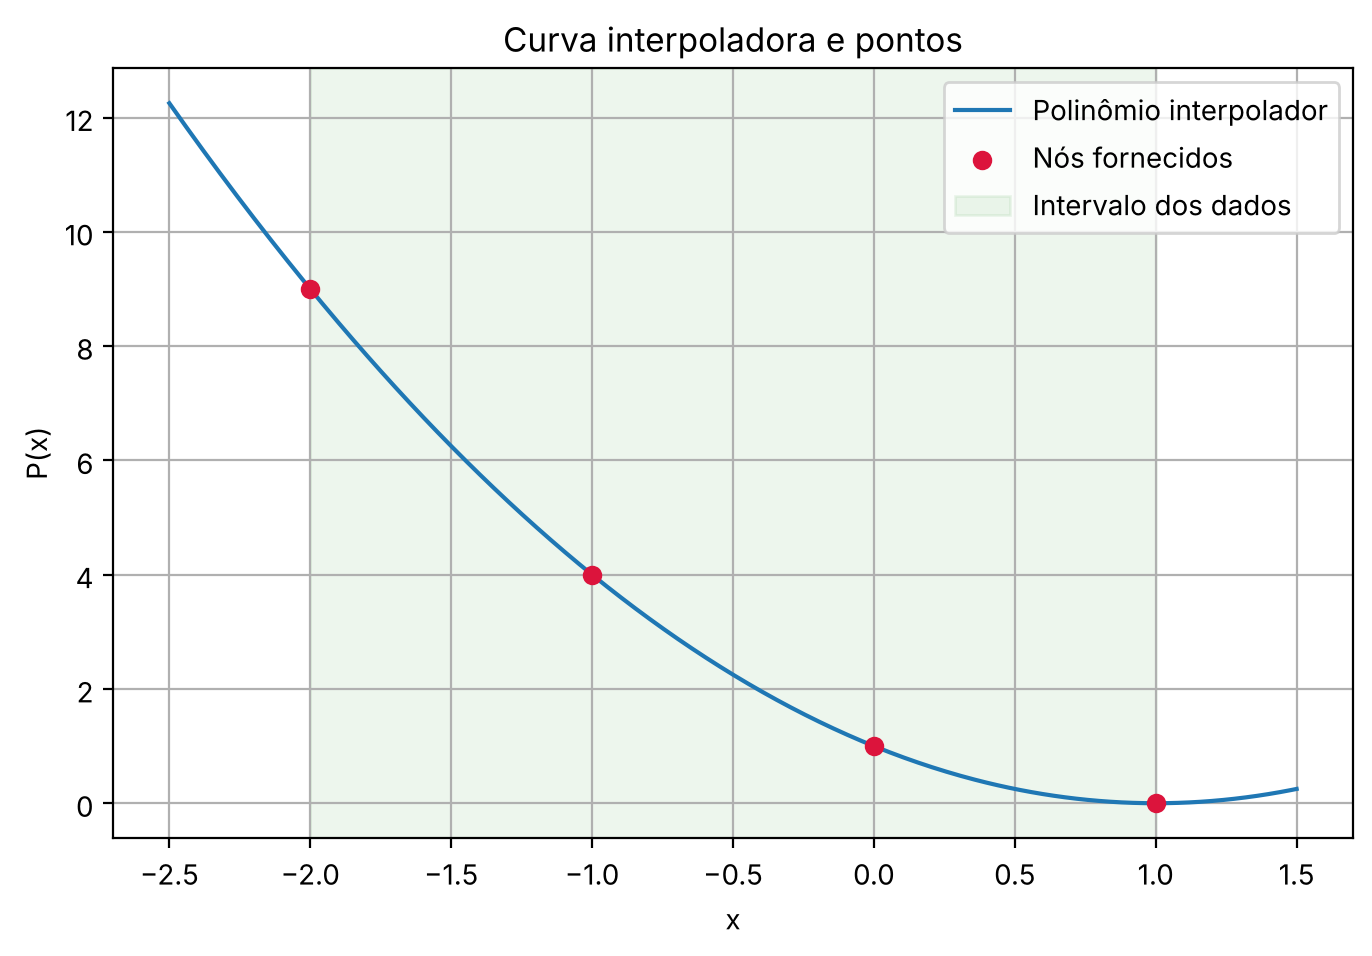

In [5]:
xx = np.linspace(x.min()-0.5, x.max()+0.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, polinomio(xx), label="Polinômio interpolador")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós fornecidos")
plt.axvspan(x.min(), x.max(), color="green", alpha=0.07, label="Intervalo dos dados")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("Curva interpoladora e pontos")
plt.grid(True); plt.legend(); plt.show()

O gráfico ajuda a perceber a forma da curva, mas uma figura pode esconder diferenças pequenas ou induzir a confiar demais em uma região sem dados. A faixa sombreada é o intervalo de interpolação; fora dela estamos extrapolando.

**Descrevam:** a curva passa pelos pontos? O comportamento fora do intervalo parece sustentado pelos dados?

**Resposta:** Sim, a curva passa pelos quatro pontos. Dentro da faixa verde ($-2\le x\le1$) ela é uma parábola decrescente, coerente com os dados. Fora dela, a curva **volta a subir** à direita de $x=1$ (o mínimo está justamente no último nó). Os dados não sustentam isso: eles só mostram a queda até $y=0$, e nada garante que o fenômeno real "vire" em $x=1$. É uma consequência da forma do polinômio, não uma informação medida.

## 6. Calcular valores intermediários

Escolham valores que não aparecem na tabela. O resultado de $P(x)$ é uma estimativa interpolada quando $x$ está entre o menor e o maior nó.

In [6]:
consultas = np.array([-1.5, -0.5, 0.5, 0.9, 2.0])
for q in consultas:
    tipo = "interpolação" if x.min() <= q <= x.max() else "extrapolação"
    print(f"P({q:4.1f}) = {polinomio(q): .6f}  ({tipo})")

P(-1.5) =  6.250000  (interpolação)
P(-0.5) =  2.250000  (interpolação)
P( 0.5) =  0.250000  (interpolação)
P( 0.9) =  0.010000  (interpolação)
P( 2.0) =  1.000000  (extrapolação)


**Tabela de registro**

| $x$ consultado | Estimativa $P(x)$ | Interpolação ou extrapolação? |
|---|---|---|
| −1,5 | 6,25 | Interpolação |
| −0,5 | 2,25 | Interpolação |
| 0,5 | 0,25 | Interpolação |
| 0,9 | 0,01 | Interpolação |
| 2,0 | 1,00 | **Extrapolação** (fora de $[-2,\,1]$) |

*Observação:* os valores coincidem com $(x-1)^2$ porque os dados são exatamente dessa parábola. Mesmo assim, o valor em $x=2$ continua sendo uma extrapolação: só vale se a hipótese "o fenômeno é uma parábola" for verdadeira.

### Atividade: comparar ferramentas

Pesquisem pelo menos **duas** ferramentas além deste código (por exemplo GeoGebra, WolframAlpha, SageMath ou calculadora online). Insiram os mesmos pontos e comparem a expressão e os valores em $x=-1{,}5$ e $x=0{,}5$.

| Ferramenta e link | Como inseriram os dados? | Expressão/resultado | O que foi fácil ou difícil? |
|---|---|---|---|
| 0. NumPy (código da atividade), [`Polynomial.fit`](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html) | Vetores `x` e `y`; grau `len(x)-1`; `.convert()` | $1-2x+x^2-4{,}3\times10^{-16}x^3$; $P(-1{,}5)=6{,}25$; $P(0{,}5)=0{,}25$ | Fácil, mas aparece o resíduo $10^{-16}$ no termo cúbico |
| 1. SymPy, [`sympy.interpolate`](https://docs.sympy.org/latest/modules/polys/polyfuncs.html#sympy.polys.polyfuncs.interpolate) | Lista de pares `[(-2,9),(-1,4),(0,1),(1,0)]` e a variável simbólica `x` | $x^2-2x+1$ **exato**; $P(-3/2)=25/4$; $P(1/2)=1/4$ | Fácil. Aritmética racional: sem resíduo, o termo cúbico some por completo |
| 2. SciPy, [`BarycentricInterpolator`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html) | Vetores `x` e `y`; chamada direta `P(q)` | $P(-1{,}5)=6{,}25$; $P(0{,}5)=0{,}25$ (não devolve os coeficientes) | Fácil para avaliar; não dá a expressão em potências. (`scipy.interpolate.lagrange`, que daria os coeficientes, está obsoleta e é instável para muitos nós) |

**Conclusão da comparação:** as três ferramentas concordaram ($6{,}25$ e $0{,}25$), diferindo só em arredondamento (SymPy é exato; NumPy/SciPy têm erro de $\sim10^{-15}$). Isso é esperado: o polinômio interpolador de 4 pontos é **único**, então qualquer ferramenta que faça interpolação polinomial deve chegar ao mesmo resultado. Se uma ferramenta devolvesse algo diferente (por exemplo, no GeoGebra, `Ajuste Polinomial` com grau menor que 3 ou `Spline`), seria regressão ou spline, não interpolação.

In [7]:
# Mesmos pontos em outras duas ferramentas: SymPy (álgebra simbólica) e SciPy (numérico)
import sympy as sp
from scipy.interpolate import BarycentricInterpolator

X = sp.symbols("x")
pontos = [(-2, 9), (-1, 4), (0, 1), (1, 0)]

# Ferramenta 1: SymPy, interpolação polinomial com aritmética exata (racional)
P_sym = sp.interpolate(pontos, X)
print("SymPy   :", sp.expand(P_sym), "| P(-1.5) =", P_sym.subs(X, sp.Rational(-3, 2)), "| P(0.5) =", P_sym.subs(X, sp.Rational(1, 2)))

# Ferramenta 2: SciPy, interpolador baricêntrico (forma de Lagrange numericamente estável)
P_sci = BarycentricInterpolator(x, y)
print("SciPy   :", f"P(-1.5) = {float(P_sci(-1.5)):.6f} | P(0.5) = {float(P_sci(0.5)):.6f}")

# Referência: o código da atividade (NumPy)
print("NumPy   :", f"P(-1.5) = {polinomio(-1.5):.6f} | P(0.5) = {polinomio(0.5):.6f}")

SymPy   : x**2 - 2*x + 1 | P(-1.5) = 25/4 | P(0.5) = 1/4
SciPy   : P(-1.5) = 6.250000 | P(0.5) = 0.250000
NumPy   : P(-1.5) = 6.250000 | P(0.5) = 0.250000


## 7. Segundo conjunto: dados de medição

Agora considere uma sequência simplificada de medições. O valor de $x$ pode representar tempo, e $y$ uma grandeza observada.

1.2 + 1.11666667·x - 0.45·x² + 0.13333333·x³
Estimativa em x=1.5: 2.312500


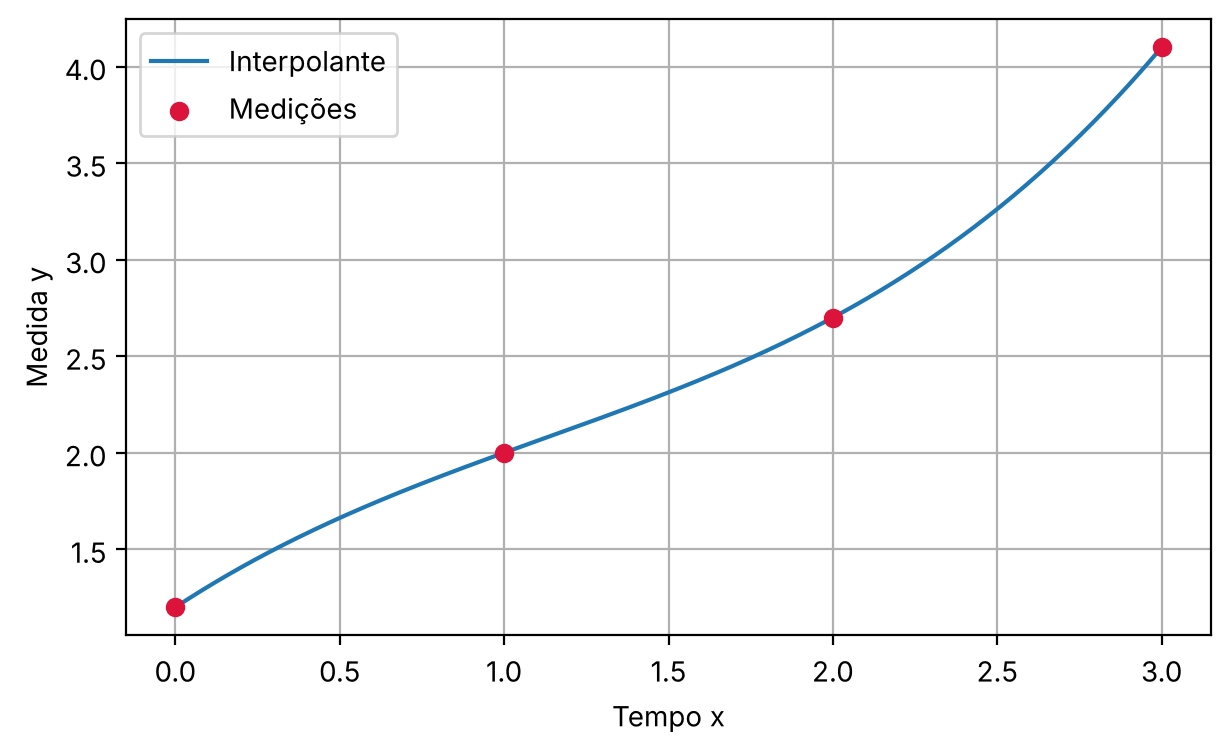

In [8]:
xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 2.7, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, deg=len(xB)-1).convert()
print(pB)
print(f"Estimativa em x=1.5: {pB(1.5):.6f}")
xb_plot = np.linspace(xB.min(), xB.max(), 300)
plt.figure(figsize=(7,4)); plt.plot(xb_plot,pB(xb_plot),label="Interpolante")
plt.scatter(xB,yB,color="crimson",label="Medições",zorder=3)
plt.xlabel("Tempo x"); plt.ylabel("Medida y"); plt.grid(True); plt.legend(); plt.show()

**Discussão:** $x=1{,}5$ está entre nós? Qual a estimativa?

**Resposta:** Sim, está entre os nós $x=1$ e $x=2$, logo é **interpolação**. A estimativa é $P_B(1{,}5)\approx 2{,}3125$, com $P_B(x)=1{,}2+1{,}1167x-0{,}45x^2+0{,}1333x^3$. Para comparação, a média simples dos vizinhos ($2{,}0$ e $2{,}7$) daria $2{,}35$: valor próximo, o que é razoável para dados que crescem de forma suave.


## 8. Experimento: alterar uma medição

Ajustem somente o valor medido em $x=2$ e observem o efeito na curva. Abaixo usamos uma alteração de $+0{,}5$; vocês podem testar outra.

Estimativa original em x=1.5: 2.312499999999999
Estimativa alterada em x=1.5: 2.59375


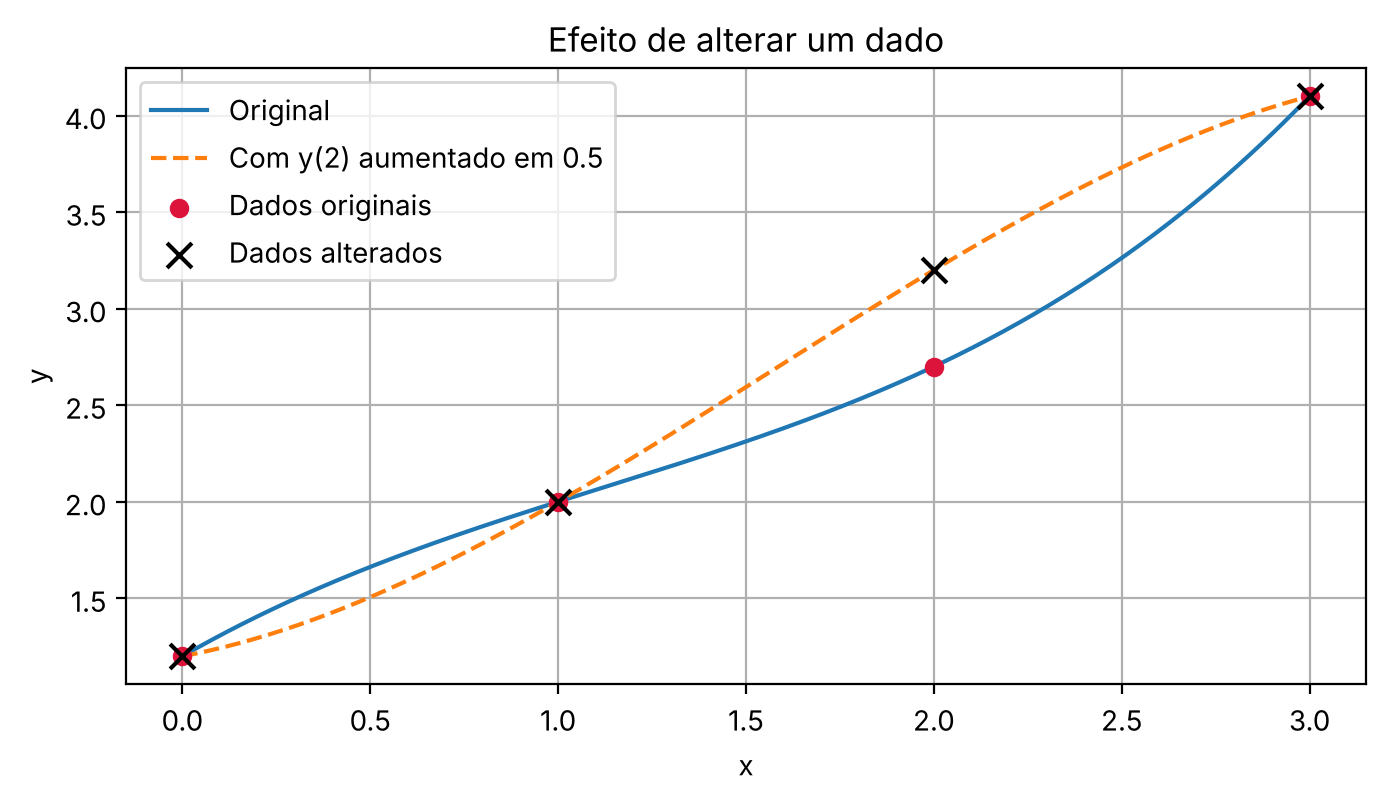

In [9]:
yB_alterado = yB.copy()
yB_alterado[2] += 0.5
pB_alterado = np.polynomial.Polynomial.fit(xB, yB_alterado, deg=len(xB)-1).convert()
print("Estimativa original em x=1.5:", pB(1.5))
print("Estimativa alterada em x=1.5:", pB_alterado(1.5))
plt.figure(figsize=(8,4))
plt.plot(xb_plot,pB(xb_plot),label="Original")
plt.plot(xb_plot,pB_alterado(xb_plot),"--",label="Com y(2) aumentado em 0.5")
plt.scatter(xB,yB,color="crimson",zorder=3,label="Dados originais")
plt.scatter(xB,yB_alterado,marker="x",s=80,color="black",zorder=4,label="Dados alterados")
plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Efeito de alterar um dado"); plt.show()

**Registrem:** qual ponto foi alterado? O que aconteceu ao valor em $x=1{,}5$? A curva mudou apenas perto do ponto alterado? Por que pequenas incertezas de medição podem ser importantes?

**Resposta:** O ponto alterado foi $(2;\,2{,}7)\to(2;\,3{,}2)$. A estimativa em $x=1{,}5$ passou de $2{,}3125$ para $2{,}59375$ (variação de $+0{,}28$, mais da metade da alteração de $0{,}5$). **A curva não mudou só perto do ponto alterado**: ela mudou em todo o intervalo, por exemplo em $x=0{,}5$ a variação foi de $-0{,}156$, e a maior diferença ($\approx0{,}53$ perto de $x=2{,}2$) foi até **maior** que a perturbação de $0{,}5$. Só nos outros nós ($x=0,1,3$) o valor não mudou, porque o polinômio é obrigado a passar por eles. A razão é que cada coeficiente depende de *todos* os dados (o polinômio é uma curva "global", não local). Consequência prática: uma pequena incerteza em uma medição se espalha e pode até ser amplificada nas estimativas entre os nós, e não dá para saber se o valor interpolado é confiável sem conhecer o erro das medições.

## 9. Quando o grau alto pode ser um problema?

Com muitos pontos, o polinômio interpolador pode oscilar entre nós, especialmente quando os pontos estão igualmente espaçados. Essa oscilação é um fenômeno conhecido como **fenômeno de Runge** em certos exemplos. Mais pontos e ajuste exato não significam sempre uma curva mais adequada.

A atividade seguinte é uma demonstração visual: comparem uma função suave com polinômios que passam por quantidades crescentes de pontos igualmente espaçados.

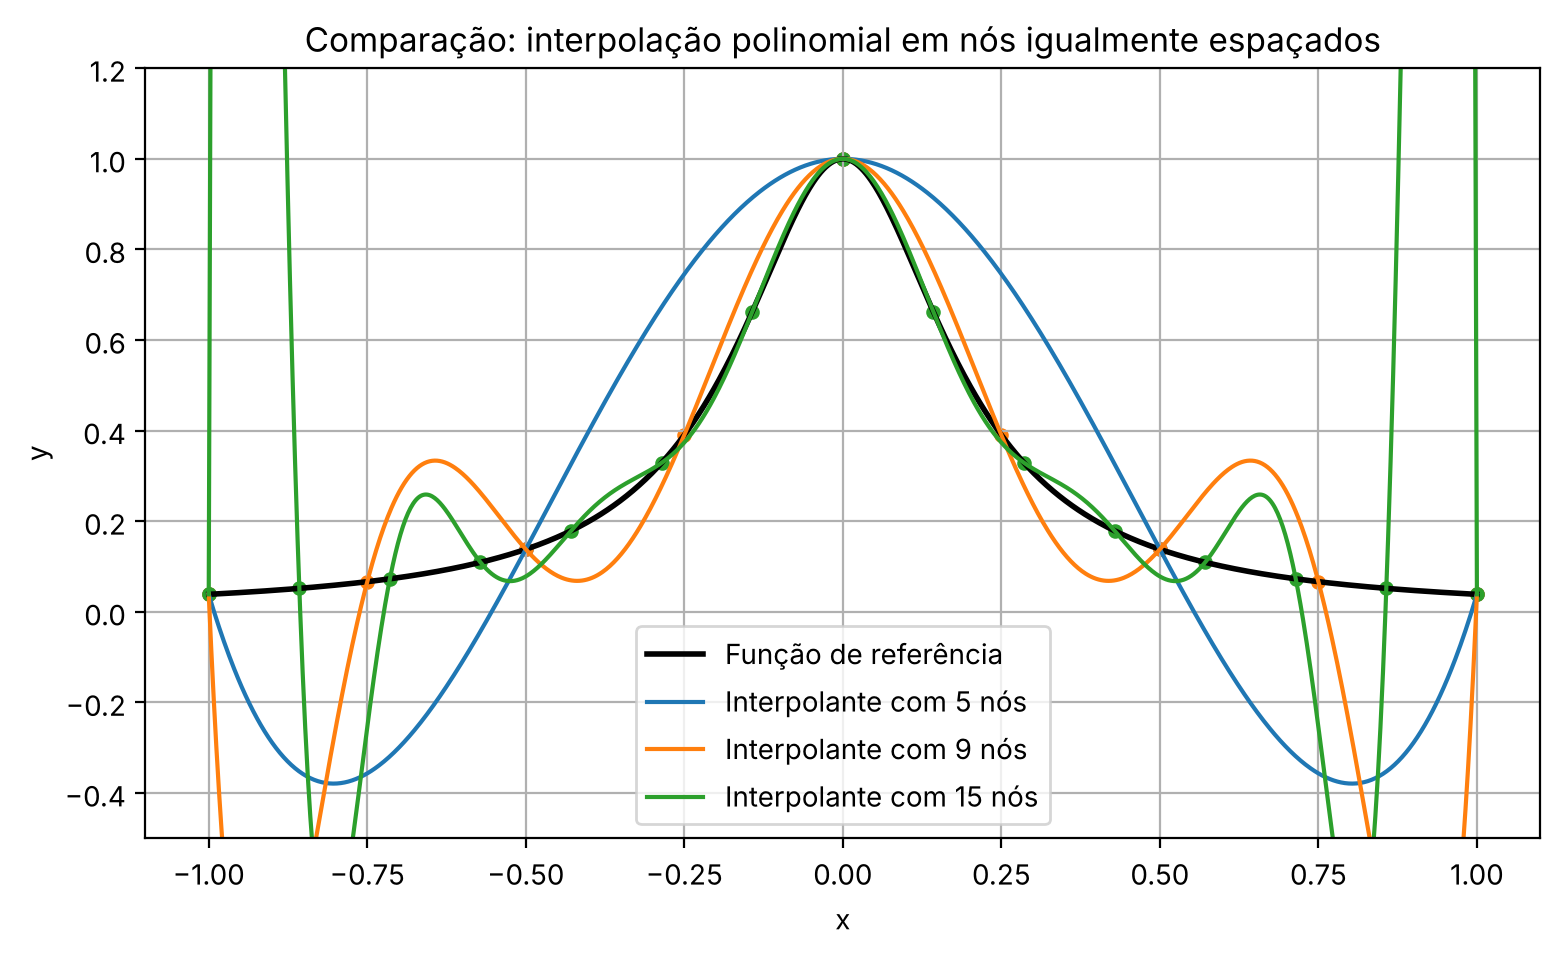

In [10]:
def f(t):
    return 1/(1+25*t**2)

t_plot = np.linspace(-1,1,1000)
plt.figure(figsize=(9,5))
plt.plot(t_plot,f(t_plot),color="black",linewidth=2,label="Função de referência")
for n in [5, 9, 15]:
    tn=np.linspace(-1,1,n)
    pn=np.polynomial.Polynomial.fit(tn,f(tn),deg=n-1).convert()
    plt.plot(t_plot,pn(t_plot),label=f"Interpolante com {n} nós")
    plt.scatter(tn,f(tn),s=18)
plt.ylim(-0.5,1.2); plt.grid(True); plt.legend(); plt.title("Comparação: interpolação polinomial em nós igualmente espaçados")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

In [11]:
# Efeito da escolha dos nós: igualmente espaçados x Chebyshev (mesma função, mesmo número de nós)
tt = np.linspace(-1, 1, 2001)
print(" n | erro máx. (igualmente espaçados) | erro máx. (Chebyshev)")
for n in [5, 9, 15, 25]:
    t_eq = np.linspace(-1, 1, n)
    t_ch = np.cos((2*np.arange(n) + 1) * np.pi / (2*n))            # nós de Chebyshev
    erros = []
    for tn in (t_eq, t_ch):
        pn = np.polynomial.Polynomial.fit(tn, f(tn), n-1)            # (sem .convert(): melhor condicionado)
        erros.append(np.max(np.abs(pn(tt) - f(tt))))
    print(f"{n:2d} | {erros[0]:32.3e} | {erros[1]:.3e}")

 n | erro máx. (igualmente espaçados) | erro máx. (Chebyshev)
 5 |                        4.384e-01 | 4.020e-01
 9 |                        1.045e+00 | 1.708e-01
15 |                        7.195e+00 | 4.660e-02
25 |                        2.572e+02 | 6.948e-03


**Observação guiada:**

- Todas as curvas interpoladoras passam pelos pontos utilizados?
- O que ocorre perto das extremidades quando aumenta o número de nós?
- Para muitos dados, que alternativas vocês investigariam (por exemplo, interpolação por partes/splines)?

**Respostas:**

- **Sim**, todas passam pelos pontos usados (erro nos nós $<10^{-11}$), mesmo a de 15 nós.
- Perto das extremidades surgem **oscilações crescentes**: o erro máximo em $[-1,1]$ sobe de $\approx0{,}44$ (5 nós) para $\approx1{,}05$ (9 nós) e $\approx7{,}2$ (15 nós), sempre perto de $x=\pm0{,}8$ a $\pm0{,}96$. Ou seja, **mais pontos pioraram o resultado**. (Na figura o eixo é cortado em 1,2, então a oscilação de 15 nós fica maior que o visível.) Isso é o fenômeno de Runge.
- Alternativas: **interpolação por partes / splines** (polinômios de grau baixo em cada trecho), **nós de Chebyshev** (mais densos nas pontas; na célula acima, com 15 nós o erro máximo cai de $\approx7{,}2$ para $\approx0{,}05$, e com 25 nós de $\approx257$ para $\approx0{,}007$: a escolha dos nós muda completamente o resultado) e **regressão** de grau baixo quando há ruído.

O objetivo é observar, não memorizar uma regra universal: o comportamento depende dos dados, dos nós e do método.

## 10. Interpolação versus regressão

Na interpolação, a curva passa pelos pontos fornecidos. Na **regressão**, escolhemos um modelo que procura representar a tendência geral, sem exigir que passe por cada observação. A regressão pode ser mais apropriada quando há ruído de medição.

| Aspecto | Interpolação | Regressão |
|---|---|---|
| Passa por todos os dados? | Sim (no caso polinomial exato) | Em geral, não |
| Uso comum | Estimar entre dados conhecidos | Representar tendência com dados ruidosos |
| Risco | Oscilação ou extrapolação ruim | Modelo inadequado ou resíduos grandes |

**Expliquem com suas palavras por que a curva interpoladora do conjunto B não prova que as medições são exatas ou sem ruído.**

**Resposta:** Porque a curva passa pelos pontos **por construção**, e não por eles serem bons: para quaisquer 4 valores de $y$ (corretos, com ruído ou até inventados) sempre existe um polinômio de grau ≤ 3 que os reproduz exatamente, como vimos no experimento da seção 8, em que o polinômio se adaptou ao valor alterado sem "reclamar". Um erro zero nos nós, portanto, não diz nada sobre a qualidade das medições; se houver ruído, o interpolador o trata como sinal e o repassa às estimativas entre os nós. Já uma regressão aceitaria resíduos para captar a tendência, o que é mais adequado quando se sabe que existe ruído.

## 11. Síntese e entrega

Escrevam uma síntese de 6–10 linhas, incluindo:
1. o que significa interpolar e a diferença para extrapolar;
2. quais ferramentas foram testadas e se concordaram;
3. o que mudou quando um dado foi alterado;
4. uma limitação observada na interpolação polinomial;
5. em que situação prática usariam o método e que cautela teriam.

**Síntese do grupo:**

Interpolar é estimar o valor de uma grandeza **dentro** do intervalo coberto pelos nós, usando um polinômio que reproduz exatamente os dados ($P(x_i)=y_i$); extrapolar é estimar **fora** desse intervalo, onde nada nos dados sustenta o comportamento da curva. Testamos NumPy, SymPy e SciPy com os mesmos pontos, e as três concordaram ($P(-1{,}5)=6{,}25$ e $P(0{,}5)=0{,}25$), diferindo apenas em arredondamento (SymPy é exato), o que confirma que o polinômio de grau ≤ $m-1$ por $m$ nós é único. Ao alterar um dado do conjunto B (+0,5 em $x=2$), a curva mudou em **todo** o intervalo, e a estimativa em $x=1{,}5$ foi de $2{,}31$ para $2{,}59$: o polinômio é global, e pequenas incertezas de medição se espalham. Como limitação, observamos o fenômeno de Runge: com nós igualmente espaçados, mais pontos (15 nós) geraram oscilações grandes perto das extremidades (erro máx. $\approx7{,}2$), apesar de o erro nos nós ser nulo. Usaríamos o método para estimar um valor entre poucas medições precisas e suaves (por exemplo, uma temperatura em um horário intermediário), com poucos nós e sem extrapolar. Com muitos dados ou com ruído, preferiríamos splines ou regressão.


### Checklist
- [x] Expliquei o papel dos nós e do polinômio interpolador.
- [x] Conferi numericamente que o polinômio reproduz os dados.
- [x] Calculei e classifiquei valores consultados como interpolação/extrapolação.
- [x] Comparei duas ferramentas com os mesmos dados.
- [x] Fiz o experimento de alteração de dado e registrei observações.
- [x] Analisei o exemplo com muitos nós e discuti limitações.

